In [7]:
import pandas as pd
from io import StringIO

with open("PSM.csv", "r", encoding="utf-8-sig") as archivo:
    lineas = archivo.readlines()

# El encabezado está correctamente formado
encabezado = lineas[0]

filas_corregidas = []

for linea in lineas[1:]:
    linea = linea.strip()

    # Quitar las comillas que envuelven toda la fila
    if linea.startswith('"') and linea.endswith('"'):
        linea = linea[1:-1]

    # Convertir comillas duplicadas "" en comillas normales "
    linea = linea.replace('""', '"')

    filas_corregidas.append(linea)

contenido_corregido = encabezado + "\n".join(filas_corregidas)

df = pd.read_csv(
    StringIO(contenido_corregido),
    sep=",",
    decimal=","
)

print(df.head())
print(df.columns)
df.info()

   cliente_etica               canal  cohorte_año  antiguedad_meses  \
0              1  VENTAS AL PERSONAL         2022                47   
1              1     INSTITUCIONALES         2022                48   
2              0     CLIENTES VARIOS         2022                45   
3              1        LICITACIONES         2022                47   
4              1            CLINICAS         2024                29   

  venta_historica  log_venta_historica  productos_no_etica_historicos  \
0     797324.0461             5.901635                            115   
1      99151.3300             4.996303                             16   
2       1468.7200             3.167235                              1   
3     123044.9600             5.090067                             10   
4       2929.8100             3.466988                              3   

   lineas_historicas venta_mensual_promedio_historica  
0                  6                       18121.0010  
1                  2  

In [8]:
import statsmodels.formula.api as smf

modelo_ps = smf.logit(
    """
    cliente_etica
    ~ antiguedad_meses
    + log_venta_historica
    + C(canal)
    + C(cohorte_año)
    """,
    data=df
).fit()

df["propensity_score"] = modelo_ps.predict(df)

         Current function value: 0.184963
         Iterations: 35


c:\Users\Usuario\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [9]:
from sklearn.neighbors import NearestNeighbors

tratados = df[df["cliente_etica"] == 1].copy()
controles = df[df["cliente_etica"] == 0].copy()

nn = NearestNeighbors(n_neighbors=1)

nn.fit(controles[["propensity_score"]])

distancias, indices = nn.kneighbors(
    tratados[["propensity_score"]]
)

controles_match = controles.iloc[indices.flatten()].copy()

matched = tratados.reset_index(drop=True)

matched["productos_control"] = controles_match[
    "productos_no_etica_historicos"
].values

In [10]:
print(df["cliente_etica"].value_counts())

print(matched.shape)

print(controles_match.shape)

cliente_etica
1    5978
0    1717
Name: count, dtype: int64
(5978, 11)
(5978, 10)


In [11]:
print("Productos")

print(matched["productos_no_etica_historicos"].mean())

print(matched["productos_control"].mean())

Productos
26.318501170960186
7.609233857477417


In [12]:
from scipy.stats import ttest_rel

ttest_rel(
    matched["productos_no_etica_historicos"],
    matched["productos_control"]
)

TtestResult(statistic=69.65384959189653, pvalue=0.0, df=5977)

In [14]:
comparacion = pd.DataFrame({
    "Tratados": [
        matched["antiguedad_meses"].mean(),
        matched["log_venta_historica"].mean(),
    ],
    "Controles": [
        controles_match["antiguedad_meses"].mean(),
        controles_match["log_venta_historica"].mean(),
    ]
},
index=[
    "Antigüedad",
    "Log Venta"
])

print(comparacion)

             Tratados  Controles
Antigüedad  39.341753  38.669957
Log Venta    4.119486   4.343193


In [15]:
import numpy as np

df["logit_ps"] = np.log(
    df["propensity_score"] /
    (1 - df["propensity_score"])
)

caliper = 0.2 * df["logit_ps"].std()

print(caliper)

1.2058417861889439


In [16]:
def smd(x1, x0):

    return (
        (x1.mean() - x0.mean()) /
        np.sqrt(
            (x1.var() + x0.var()) / 2
        )
    )

In [17]:
print("Antigüedad")

print(
    smd(
        tratados["antiguedad_meses"],
        controles["antiguedad_meses"]
    )
)

print(
    smd(
        matched["antiguedad_meses"],
        controles_match["antiguedad_meses"]
    )
)

Antigüedad
0.5085904786682106
0.052341336229316575


In [18]:
import pandas as pd
import numpy as np

def smd(x1, x0):
    return (
        (x1.mean() - x0.mean()) /
        np.sqrt((x1.var() + x0.var()) / 2)
    )

variables = [
    "antiguedad_meses",
    "log_venta_historica"
]

resultado = []

for var in variables:

    antes = smd(
        tratados[var],
        controles[var]
    )

    despues = smd(
        matched[var],
        controles_match[var]
    )

    resultado.append({
        "Variable": var,
        "SMD Antes": antes,
        "SMD Después": despues
    })

balance = pd.DataFrame(resultado)

balance["|SMD Antes|"] = balance["SMD Antes"].abs()
balance["|SMD Después|"] = balance["SMD Después"].abs()

balance = balance[
    [
        "Variable",
        "SMD Antes",
        "SMD Después",
        "|SMD Antes|",
        "|SMD Después|"
    ]
]

print(balance.round(3))

              Variable  SMD Antes  SMD Después  |SMD Antes|  |SMD Después|
0     antiguedad_meses      0.509        0.052        0.509          0.052
1  log_venta_historica      1.052       -0.312        1.052          0.312


In [19]:
def interpretar(smd):

    smd = abs(smd)

    if smd < 0.10:
        return "Excelente"

    elif smd < 0.20:
        return "Aceptable"

    else:
        return "Desbalance"

balance["Balance"] = balance["SMD Después"].apply(interpretar)

print(balance.round(3))

              Variable  SMD Antes  SMD Después  |SMD Antes|  |SMD Después|  \
0     antiguedad_meses      0.509        0.052        0.509          0.052   
1  log_venta_historica      1.052       -0.312        1.052          0.312   

      Balance  
0   Excelente  
1  Desbalance  


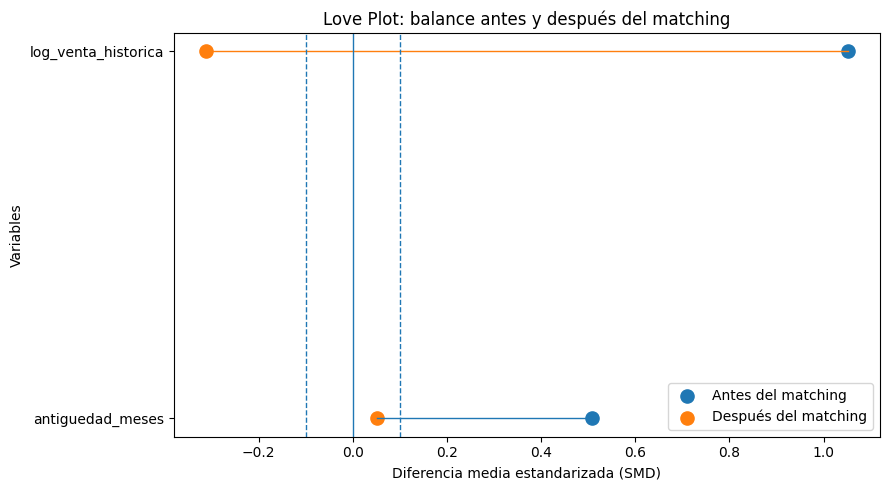

In [21]:
import matplotlib.pyplot as plt

# Ordenar para que las variables con mayor desbalance aparezcan arriba
balance_plot = balance.sort_values(
    "|SMD Antes|",
    ascending=True
).copy()

plt.figure(figsize=(9, 5))

# Puntos antes del matching
plt.scatter(
    balance_plot["SMD Antes"],
    balance_plot["Variable"],
    label="Antes del matching",
    s=90
)

# Puntos después del matching
plt.scatter(
    balance_plot["SMD Después"],
    balance_plot["Variable"],
    label="Después del matching",
    s=90
)

# Línea entre antes y después
for _, fila in balance_plot.iterrows():
    plt.plot(
        [fila["SMD Antes"], fila["SMD Después"]],
        [fila["Variable"], fila["Variable"]],
        linewidth=1
    )

# Límites de balance aceptable
plt.axvline(0, linewidth=1)
plt.axvline(0.10, linestyle="--", linewidth=1)
plt.axvline(-0.10, linestyle="--", linewidth=1)

plt.xlabel("Diferencia media estandarizada (SMD)")
plt.ylabel("Variables")
plt.title("Love Plot: balance antes y después del matching")
plt.legend()
plt.tight_layout()
plt.savefig(
    "love_plot_psm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [22]:
import pandas as pd
import numpy as np

def smd(x1, x0):
    x1 = pd.to_numeric(x1, errors="coerce")
    x0 = pd.to_numeric(x0, errors="coerce")

    varianza_promedio = (
        x1.var(ddof=1) + x0.var(ddof=1)
    ) / 2

    if varianza_promedio == 0 or np.isnan(varianza_promedio):
        return 0.0

    return (
        x1.mean() - x0.mean()
    ) / np.sqrt(varianza_promedio)


# -------------------------------
# Variables numéricas
# -------------------------------

numericas = [
    "antiguedad_meses",
    "log_venta_historica"
]

resultados_balance = []

for variable in numericas:
    resultados_balance.append({
        "Variable": variable,
        "SMD Antes": smd(
            tratados[variable],
            controles[variable]
        ),
        "SMD Después": smd(
            matched[variable],
            controles_match[variable]
        )
    })


# -------------------------------
# Variables categóricas
# -------------------------------

categoricas = [
    "canal",
    "cohorte_año"
]

for variable in categoricas:

    categorias = sorted(
        df[variable]
        .dropna()
        .unique()
    )

    for categoria in categorias:

        tratados_antes = (
            tratados[variable] == categoria
        ).astype(int)

        controles_antes = (
            controles[variable] == categoria
        ).astype(int)

        tratados_despues = (
            matched[variable] == categoria
        ).astype(int)

        controles_despues = (
            controles_match[variable] == categoria
        ).astype(int)

        resultados_balance.append({
            "Variable": f"{variable}: {categoria}",
            "SMD Antes": smd(
                tratados_antes,
                controles_antes
            ),
            "SMD Después": smd(
                tratados_despues,
                controles_despues
            )
        })


balance_completo = pd.DataFrame(resultados_balance)

balance_completo["|SMD Antes|"] = (
    balance_completo["SMD Antes"].abs()
)

balance_completo["|SMD Después|"] = (
    balance_completo["SMD Después"].abs()
)


def interpretar(valor):
    valor = abs(valor)

    if valor < 0.10:
        return "Excelente"
    elif valor < 0.20:
        return "Aceptable"
    else:
        return "Desbalance"


balance_completo["Balance"] = (
    balance_completo["SMD Después"]
    .apply(interpretar)
)

print(
    balance_completo
    .sort_values("|SMD Después|", ascending=False)
    .round(3)
)

                     Variable  SMD Antes  SMD Después  |SMD Antes|  \
9            canal: FARMACIAS      1.918        0.385        1.918   
1         log_venta_historica      1.052       -0.312        1.052   
10     canal: INSTITUCIONALES     -0.050       -0.278        0.050   
8       canal: DISTRIBUIDORES     -0.027       -0.152        0.027   
6             canal: CLINICAS     -0.105       -0.148        0.105   
11        canal: LICITACIONES      0.025       -0.128        0.025   
22          cohorte_año: 2025     -0.283       -0.110        0.283   
20          cohorte_año: 2023     -0.172        0.085        0.172   
21          cohorte_año: 2024     -0.289        0.053        0.289   
0            antiguedad_meses      0.509        0.052        0.509   
18        canal: VETERINARIAS     -0.107       -0.035        0.107   
5      canal: CLIENTES VARIOS     -1.122       -0.034        1.122   
23          cohorte_año: 2026     -0.051        0.031        0.051   
19          cohorte_

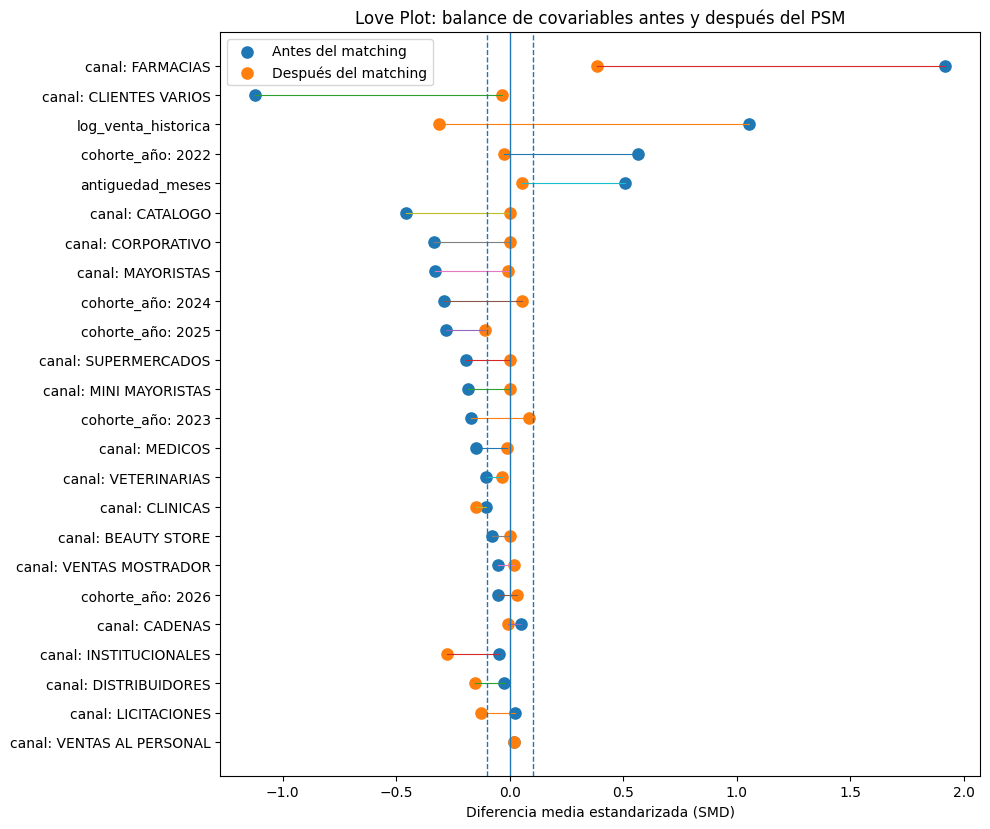

In [23]:
balance_plot = (
    balance_completo
    .sort_values("|SMD Antes|", ascending=True)
    .copy()
)

plt.figure(
    figsize=(10, max(7, len(balance_plot) * 0.35))
)

plt.scatter(
    balance_plot["SMD Antes"],
    balance_plot["Variable"],
    label="Antes del matching",
    s=65
)

plt.scatter(
    balance_plot["SMD Después"],
    balance_plot["Variable"],
    label="Después del matching",
    s=65
)

for _, fila in balance_plot.iterrows():
    plt.plot(
        [fila["SMD Antes"], fila["SMD Después"]],
        [fila["Variable"], fila["Variable"]],
        linewidth=0.8
    )

plt.axvline(0, linewidth=1)
plt.axvline(0.10, linestyle="--", linewidth=1)
plt.axvline(-0.10, linestyle="--", linewidth=1)

plt.xlabel("Diferencia media estandarizada (SMD)")
plt.ylabel("")
plt.title("Love Plot: balance de covariables antes y después del PSM")
plt.legend()
plt.tight_layout()

plt.savefig(
    "love_plot_psm_completo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
balance_completo[
    balance_completo["|SMD Después|"] >= 0.10
].sort_values(
    "|SMD Después|",
    ascending=False
)

,Variable,SMD Antes,SMD Después,|SMD Antes|,|SMD Después|,Balance
9,canal: FARMACIAS,1.918476,0.385342,1.918476,0.385342,Desbalance
1,log_venta_historica,1.051656,-0.312017,1.051656,0.312017,Desbalance
10,canal: INSTITUCIONALES,-0.049780,-0.278049,0.049780,0.278049,Desbalance
8,canal: DISTRIBUIDORES,-0.027493,-0.151970,0.027493,0.151970,Aceptable
6,canal: CLINICAS,-0.105042,-0.147697,0.105042,0.147697,Aceptable
11,canal: LICITACIONES,0.024716,-0.128169,0.024716,0.128169,Aceptable
22,cohorte_año: 2025,-0.282996,-0.109614,0.282996,0.109614,Aceptable


In [25]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df_psm = df.dropna(
    subset=[
        "cliente_etica",
        "canal",
        "cohorte_año",
        "antiguedad_meses",
        "log_venta_historica"
    ]
).copy()

modelo_ps = smf.logit(
    formula="""
        cliente_etica
        ~ antiguedad_meses
        + log_venta_historica
        + C(canal)
        + C(cohorte_año)
    """,
    data=df_psm
).fit()

df_psm["propensity_score"] = modelo_ps.predict(df_psm)

# Evitar logaritmos infinitos
epsilon = 1e-6

df_psm["propensity_score"] = df_psm[
    "propensity_score"
].clip(epsilon, 1 - epsilon)

df_psm["logit_ps"] = np.log(
    df_psm["propensity_score"]
    / (1 - df_psm["propensity_score"])
)

caliper = 0.20 * df_psm["logit_ps"].std()

print("Caliper:", caliper)

         Current function value: 0.184963
         Iterations: 35
Caliper: 0.889831144262222


c:\Users\Usuario\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [26]:
tratados_ps = df_psm[
    df_psm["cliente_etica"] == 1
].copy()

controles_ps = df_psm[
    df_psm["cliente_etica"] == 0
].copy()

limite_inferior = max(
    tratados_ps["propensity_score"].min(),
    controles_ps["propensity_score"].min()
)

limite_superior = min(
    tratados_ps["propensity_score"].max(),
    controles_ps["propensity_score"].max()
)

df_soporte = df_psm[
    df_psm["propensity_score"].between(
        limite_inferior,
        limite_superior
    )
].copy()

print("Soporte común:", limite_inferior, limite_superior)
print(df_soporte["cliente_etica"].value_counts())

Soporte común: 0.0014372050502400471 0.9989091667253864
cliente_etica
1    5846
0    1287
Name: count, dtype: int64


In [27]:
def matching_exacto_sin_reemplazo(
    data,
    caliper,
    columnas_exactas=("canal", "cohorte_año"),
    random_state=42
):
    tratados = data[
        data["cliente_etica"] == 1
    ].copy()

    controles = data[
        data["cliente_etica"] == 0
    ].copy()

    # Aleatorizar el orden para que el resultado no dependa
    # del orden original de la base
    tratados = tratados.sample(
        frac=1,
        random_state=random_state
    )

    controles_disponibles = set(controles.index)

    pares = []

    for indice_tratado, fila_tratado in tratados.iterrows():

        candidatos = controles.loc[
            list(controles_disponibles)
        ]

        # Matching exacto por canal y cohorte
        for columna in columnas_exactas:
            candidatos = candidatos[
                candidatos[columna] == fila_tratado[columna]
            ]

        if candidatos.empty:
            continue

        distancias = (
            candidatos["logit_ps"]
            - fila_tratado["logit_ps"]
        ).abs()

        indice_control = distancias.idxmin()
        distancia_minima = distancias.loc[indice_control]

        if distancia_minima <= caliper:
            pares.append({
                "indice_tratado": indice_tratado,
                "indice_control": indice_control,
                "distancia_logit": distancia_minima
            })

            # Impedir que el mismo control vuelva a utilizarse
            controles_disponibles.remove(indice_control)

    return pd.DataFrame(pares)

In [28]:
pares_match = matching_exacto_sin_reemplazo(
    data=df_soporte,
    caliper=caliper,
    columnas_exactas=("canal", "cohorte_año"),
    random_state=42
)

print("Cantidad de parejas:", len(pares_match))
print(pares_match["distancia_logit"].describe())

Cantidad de parejas: 540
count    540.000000
mean       0.311048
std        0.284222
min        0.000011
25%        0.041230
50%        0.230689
75%        0.569942
max        0.889145
Name: distancia_logit, dtype: float64


In [29]:
matched_tratados = (
    df_soporte
    .loc[pares_match["indice_tratado"]]
    .reset_index(drop=True)
)

matched_controles = (
    df_soporte
    .loc[pares_match["indice_control"]]
    .reset_index(drop=True)
)

print(matched_tratados.shape)
print(matched_controles.shape)

print(
    matched_tratados["canal"]
    .value_counts()
    .sort_index()
    .equals(
        matched_controles["canal"]
        .value_counts()
        .sort_index()
    )
)

print(
    matched_tratados["cohorte_año"]
    .value_counts()
    .sort_index()
    .equals(
        matched_controles["cohorte_año"]
        .value_counts()
        .sort_index()
    )
)

(540, 11)
(540, 11)
True
True


In [30]:
def smd(x1, x0):
    x1 = pd.to_numeric(x1, errors="coerce")
    x0 = pd.to_numeric(x0, errors="coerce")

    varianza_promedio = (
        x1.var(ddof=1) + x0.var(ddof=1)
    ) / 2

    if varianza_promedio == 0 or np.isnan(varianza_promedio):
        return 0.0

    return (
        x1.mean() - x0.mean()
    ) / np.sqrt(varianza_promedio)


variables_continuas = [
    "antiguedad_meses",
    "log_venta_historica"
]

resultado_balance = []

tratados_antes = df_soporte[
    df_soporte["cliente_etica"] == 1
]

controles_antes = df_soporte[
    df_soporte["cliente_etica"] == 0
]

for variable in variables_continuas:
    resultado_balance.append({
        "Variable": variable,
        "SMD Antes": smd(
            tratados_antes[variable],
            controles_antes[variable]
        ),
        "SMD Después": smd(
            matched_tratados[variable],
            matched_controles[variable]
        )
    })

balance_nuevo = pd.DataFrame(resultado_balance)

balance_nuevo["|SMD Antes|"] = (
    balance_nuevo["SMD Antes"].abs()
)

balance_nuevo["|SMD Después|"] = (
    balance_nuevo["SMD Después"].abs()
)

print(balance_nuevo.round(3))

              Variable  SMD Antes  SMD Después  |SMD Antes|  |SMD Después|
0     antiguedad_meses      0.294        0.007        0.294          0.007
1  log_venta_historica      0.864        0.135        0.864          0.135


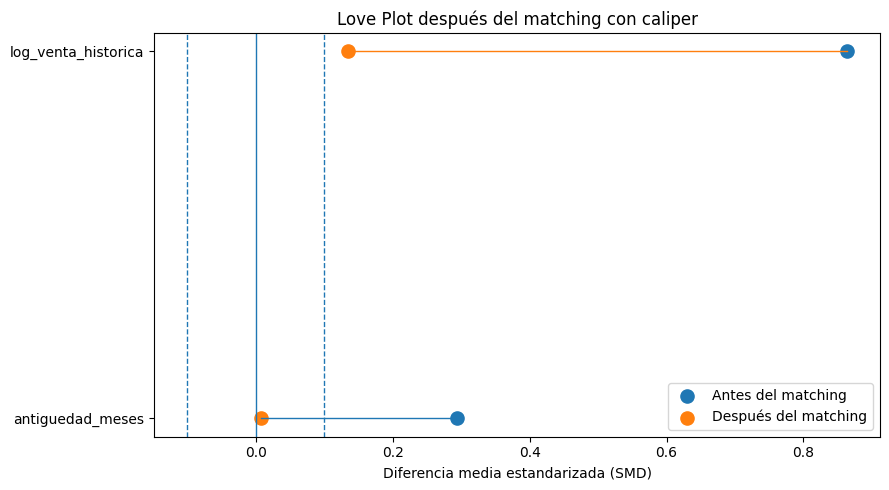

In [31]:
import matplotlib.pyplot as plt

balance_plot = balance_nuevo.sort_values(
    "|SMD Antes|",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.scatter(
    balance_plot["SMD Antes"],
    balance_plot["Variable"],
    label="Antes del matching",
    s=90
)

plt.scatter(
    balance_plot["SMD Después"],
    balance_plot["Variable"],
    label="Después del matching",
    s=90
)

for _, fila in balance_plot.iterrows():
    plt.plot(
        [fila["SMD Antes"], fila["SMD Después"]],
        [fila["Variable"], fila["Variable"]],
        linewidth=1
    )

plt.axvline(0, linewidth=1)
plt.axvline(0.10, linestyle="--", linewidth=1)
plt.axvline(-0.10, linestyle="--", linewidth=1)

plt.xlabel("Diferencia media estandarizada (SMD)")
plt.ylabel("")
plt.title("Love Plot después del matching con caliper")
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
matched_final = matched_tratados.copy()

matched_final["productos_control"] = (
    matched_controles["productos_no_etica_historicos"].values
)

matched_final["lineas_control"] = (
    matched_controles["lineas_historicas"].values
)

matched_final["venta_control"] = (
    matched_controles["venta_mensual_promedio_historica"].values
)

In [33]:
from scipy.stats import ttest_rel

variables = [
    (
        "productos_no_etica_historicos",
        "productos_control"
    ),
    (
        "lineas_historicas",
        "lineas_control"
    ),
    (
        "venta_mensual_promedio_historica",
        "venta_control"
    )
]

for tratada, control in variables:

    diferencia = (
        matched_final[tratada]
        -
        matched_final[control]
    )

    print("=" * 70)

    print(tratada)

    print("ATT =", diferencia.mean())

    print("Desvío =", diferencia.std())

    print(
        ttest_rel(
            matched_final[tratada],
            matched_final[control]
        )
    )

productos_no_etica_historicos
ATT = 3.5555555555555554
Desvío = 9.825880533683176
TtestResult(statistic=8.408777659758554, pvalue=3.7218920134740296e-16, df=539)
lineas_historicas
ATT = 1.5222222222222221
Desvío = 1.242964119394707
TtestResult(statistic=28.458784403677704, pvalue=1.9037275109017977e-109, df=539)


TypeError: unsupported operand type(s) for -: 'str' and 'str'

In [34]:
import pandas as pd
from scipy.stats import ttest_rel

columnas_numericas = [
    "productos_no_etica_historicos",
    "productos_control",
    "lineas_historicas",
    "lineas_control",
    "venta_mensual_promedio_historica",
    "venta_control"
]

for columna in columnas_numericas:
    matched_final[columna] = (
        matched_final[columna]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .str.strip()
    )

    matched_final[columna] = pd.to_numeric(
        matched_final[columna],
        errors="coerce"
    )

In [35]:
variables = [
    (
        "Productos No Ética",
        "productos_no_etica_historicos",
        "productos_control"
    ),
    (
        "Líneas históricas",
        "lineas_historicas",
        "lineas_control"
    ),
    (
        "Venta mensual promedio",
        "venta_mensual_promedio_historica",
        "venta_control"
    )
]

resultados_att = []

for nombre, tratada, control in variables:

    datos_modelo = matched_final[
        [tratada, control]
    ].dropna()

    diferencia = (
        datos_modelo[tratada]
        - datos_modelo[control]
    )

    test = ttest_rel(
        datos_modelo[tratada],
        datos_modelo[control]
    )

    resultados_att.append({
        "Variable": nombre,
        "N parejas": len(datos_modelo),
        "Media Ética": datos_modelo[tratada].mean(),
        "Media Control": datos_modelo[control].mean(),
        "ATT": diferencia.mean(),
        "Desvío diferencias": diferencia.std(ddof=1),
        "t": test.statistic,
        "p-value": test.pvalue
    })

resultado_att = pd.DataFrame(resultados_att)

print(resultado_att.round(3))

                 Variable  N parejas  Media Ética  Media Control       ATT  \
0      Productos No Ética        540        9.215          5.659     3.556   
1       Líneas históricas        540        2.994          1.472     1.522   
2  Venta mensual promedio        540     2219.058       3591.414 -1372.356   

   Desvío diferencias       t  p-value  
0               9.826   8.409    0.000  
1               1.243  28.459    0.000  
2           18682.070  -1.707    0.088  


In [36]:
import numpy as np
import pandas as pd

def bootstrap_att(df, tratada, control, n_boot=5000, seed=42):

    np.random.seed(seed)

    atts = []

    n = len(df)

    for _ in range(n_boot):

        muestra = df.sample(
            n=n,
            replace=True
        )

        att = (
            muestra[tratada]
            -
            muestra[control]
        ).mean()

        atts.append(att)

    atts = np.array(atts)

    return {
        "ATT": atts.mean(),
        "IC95_inf": np.percentile(atts, 2.5),
        "IC95_sup": np.percentile(atts, 97.5),
        "Std.Error": atts.std(ddof=1)
    }

In [37]:
resultados = []

analisis = [
    (
        "Productos No Ética",
        "productos_no_etica_historicos",
        "productos_control"
    ),
    (
        "Líneas",
        "lineas_historicas",
        "lineas_control"
    ),
    (
        "Venta Mensual",
        "venta_mensual_promedio_historica",
        "venta_control"
    )
]

for nombre, tratada, control in analisis:

    r = bootstrap_att(
        matched_final,
        tratada,
        control,
        n_boot=5000
    )

    r["Variable"] = nombre

    resultados.append(r)

bootstrap_resultados = pd.DataFrame(resultados)

bootstrap_resultados = bootstrap_resultados[
    [
        "Variable",
        "ATT",
        "IC95_inf",
        "IC95_sup",
        "Std.Error"
    ]
]

print(
    bootstrap_resultados.round(3)
)

             Variable       ATT  IC95_inf  IC95_sup  Std.Error
0  Productos No Ética     3.552     2.761     4.393      0.420
1              Líneas     1.523     1.415     1.630      0.054
2       Venta Mensual -1367.321 -3180.995   -14.051    823.452


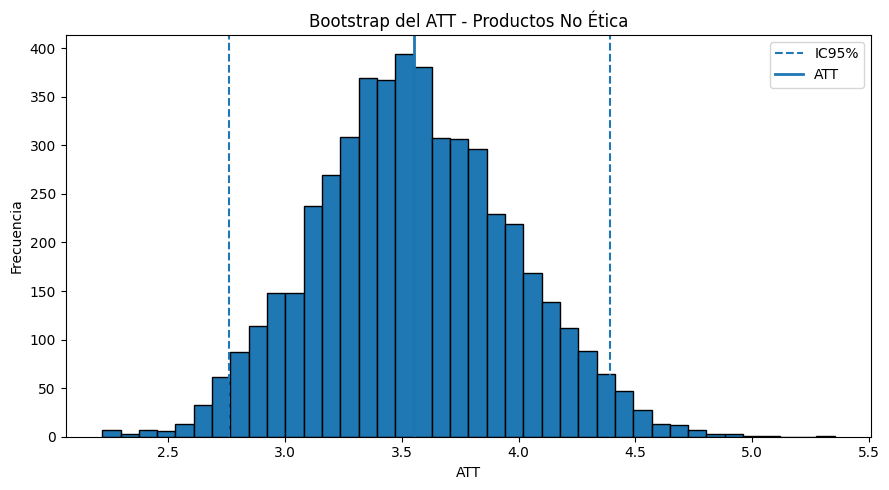

In [38]:
import matplotlib.pyplot as plt

np.random.seed(42)

atts = []

for _ in range(5000):

    muestra = matched_final.sample(
        len(matched_final),
        replace=True
    )

    atts.append(
        (
            muestra["productos_no_etica_historicos"]
            -
            muestra["productos_control"]
        ).mean()
    )

plt.figure(figsize=(9,5))

plt.hist(
    atts,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    np.percentile(atts,2.5),
    linestyle="--",
    label="IC95%"
)

plt.axvline(
    np.percentile(atts,97.5),
    linestyle="--"
)

plt.axvline(
    np.mean(atts),
    linewidth=2,
    label="ATT"
)

plt.title(
    "Bootstrap del ATT - Productos No Ética"
)

plt.xlabel("ATT")

plt.ylabel("Frecuencia")

plt.legend()

plt.tight_layout()

plt.show()

In [40]:
print(df.columns.tolist())
print(matched_tratados.columns.tolist())

['cliente_etica', 'canal', 'cohorte_año', 'antiguedad_meses', 'venta_historica', 'log_venta_historica', 'productos_no_etica_historicos', 'lineas_historicas', 'venta_mensual_promedio_historica', 'propensity_score', 'logit_ps']
['cliente_etica', 'canal', 'cohorte_año', 'antiguedad_meses', 'venta_historica', 'log_venta_historica', 'productos_no_etica_historicos', 'lineas_historicas', 'venta_mensual_promedio_historica', 'propensity_score', 'logit_ps']


In [41]:
parejas_did = pd.DataFrame({
    "id_pareja": range(1, len(matched_tratados) + 1),

    "cliente_tratado": (
        matched_tratados["codigo_cliente"].values
    ),

    "cliente_control": (
        matched_controles["codigo_cliente"].values
    ),

    "fecha_evento": pd.to_datetime(
        matched_tratados["fecha_primer_etica"]
    ).values
})

print(parejas_did.head())
print(parejas_did.shape)

KeyError: 'codigo_cliente'